## Redes Neurais Artificiais 2026.2

- **Disciplina**: Redes Neurais Artificiais 2026.2
- **Professora**: Elloá B. Guedes (ebgcosta@uea.edu.br)  
- **Github**: http://github.com/elloa  
        

Levando em conta a base de dados **_Dry Bean Dataset_**, esta segunda parte do Projeto Prático 2.2 diz respeito à proposição e avaliação de múltiplas redes neurais artificiais do tipo Feedforward Multilayer Perceptron para o problema da classificação multiclasse de variedades de feijão seco a partir de características geométricas extraídas de imagens dos grãos.

## Testando Redes Neurais com os Atributos Numéricos

1. Abra a base de dados em questão
2. Verifique que todos os atributos preditores são numéricos. O único atributo categórico é o alvo (`Class`), que não deve entrar em X
3. Armazene o atributo alvo em uma variável y e os atributos preditores em uma variável X
4. Efetue uma partição holdout 70/30 com o sklearn, distribuindo os exemplos de maneira aleatória e estratificada (`stratify=y`), com `random_state` fixo para reprodutibilidade
5. Efetue o escalonamento dos atributos

### Escalonando os atributos

O treinamento de uma rede neural artificial é mais eficiente quando os valores que lhes são fornecidos como entrada são pequenos e estão em escalas semelhantes, pois isto favorece a convergência. Isto é feito escalonando-se os atributos, mas precisa ser feito de maneira cautelosa, para que informações do conjunto de teste não sejam fornecidas no treinamento.

Há duas estratégias para tal escalonamento: normalização (que leva os valores ao intervalo [0,1]) e padronização (que centraliza os dados em média 0 e desvio padrão 1). Ambas possuem características particulares, vantagens e limitações, como é possível ver aqui: https://www.analyticsvidhya.com/blog/2020/04/feature-scaling-machine-learning-normalization-standardization/

No nosso caso, vamos usar a padronização. Assim, com os atributos preditores do treinamento, isto é, X_train, deve-se subtrair a média e dividir pelo desvio padrão. Para tanto, use o StandardScaler e ajuste-o com os dados do conjunto de treino (fit), transformando-os em seguida (transform). Depois, apenas transforme os dados do conjunto de teste (transform), usando a média e o desvio padrão calculados no treino, sem chamar o fit novamente.

Se todo o conjunto X for utilizado na padronização, a rede neural receberá informações do conjunto de teste por meio da média e do desvio padrão utilizados para preparar os dados de treinamento, o que não é desejável (vazamento de dados, ou *data leakage*).


### Continuando

1. Treine uma rede neural multilayer perceptron para este problema com uma única camada oculta de dez neurônios
    1.1 Utilize a função de ativação ReLU  
    1.2 Utilize o solver Adam    
    1.3 Imprima o passo a passo do treinamento 
    1.4 Utilize o número máximo de épocas igual a 300
2. Com o modelo em questão, após o treinamento, apresente os resultados para o conjunto de teste:  
    2.1 Matriz de confusão  
    2.2 Acurácia  
    2.3 F-Score (F1)  
    2.4 Precisão  
    2.5 Revocação   
3. Repita o treinamento da mesma rede anterior sem imprimir o passo a passo por 10 vezes  
    3.1 Cada uma destas repetições deve ser feita com uma nova partição holdout 70/30 estratificada, e o escalonamento deve ser reajustado com os dados de treino de cada partição  
    3.2 Apresente a média e o desvio padrão da acurácia e do F-Score para o conjunto de teste  
4. Repita por 10 vezes o treinamento desta mesma rede, mas utilizando o otimizador SGD, com as mesmas 10 partições do item anterior  
    4.1 Apresente a média e o desvio padrão da acurácia e do F-Score para o conjunto de teste  
5. Houve influência da escolha do otimizador no desempenho da rede? Justifique com as médias e os desvios padrão obtidos

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

#### Testando Redes Neurais com os Atributos Numéricos

In [29]:

# Item 1 — Abrindo a base de dados

df = pd.read_excel("Dry_Bean_Dataset.xlsx")
df.head(10)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER
5,30279,634.927,212.560556,181.510182,1.171067,0.520401,30600,196.347702,0.775688,0.989510,0.943852,0.923726,0.007020,0.003153,0.853270,0.999236,SEKER
6,30477,670.033,211.050155,184.039050,1.146768,0.489478,30970,196.988633,0.762402,0.984081,0.853080,0.933374,0.006925,0.003242,0.871186,0.999049,SEKER
7,30519,629.727,212.996755,182.737204,1.165591,0.513760,30847,197.124320,0.770682,0.989367,0.967109,0.925480,0.006979,0.003158,0.856514,0.998345,SEKER
8,30685,635.681,213.534145,183.157146,1.165852,0.514081,31044,197.659696,0.771561,0.988436,0.954240,0.925658,0.006959,0.003152,0.856844,0.998953,SEKER
9,30834,631.934,217.227813,180.897469,1.200834,0.553642,31120,198.139012,0.783683,0.990810,0.970278,0.912125,0.007045,0.003008,0.831973,0.999061,SEKER


In [30]:

# Item 2 — Verificando os tipos dos atributos preditores

preditores = df.drop(columns=["Class"])

print("Tipos dos atributos preditores:")
print(preditores.dtypes)

print("\nTodos os preditores são numéricos:",
      all(pd.api.types.is_numeric_dtype(tipo)
          for tipo in preditores.dtypes))

print(f"\nTipo do atributo-alvo: {df['Class'].dtype}")


Tipos dos atributos preditores:
Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRation       float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
dtype: object

Todos os preditores são numéricos: True

Tipo do atributo-alvo: str


In [31]:

# Item 3 — Separando os atributos preditores (X) e o alvo (y)

X = df.drop(columns=["Class"])
y = df["Class"]

print("Dimensões de X:", X.shape)
print("Dimensões de y:", y.shape)

print(f"\nClasses presentes: {y.unique()}")


Dimensões de X: (13611, 16)
Dimensões de y: (13611,)

Classes presentes: <StringArray>
['SEKER', 'BARBUNYA', 'BOMBAY', 'CALI', 'HOROZ', 'SIRA', 'DERMASON']
Length: 7, dtype: str


In [32]:

# Item 4 — Realizando a partição holdout 70/30 estratificada

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

print("Conjunto de treinamento:", X_train.shape)
print("Conjunto de teste:", X_test.shape)

print("\nDistribuição das classes no treinamento (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nDistribuição das classes no teste (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))


Conjunto de treinamento: (9527, 16)
Conjunto de teste: (4084, 16)

Distribuição das classes no treinamento (%):
Class
DERMASON    26.05
SIRA        19.37
SEKER       14.89
HOROZ       14.17
CALI        11.98
BARBUNYA     9.71
BOMBAY       3.83
Name: proportion, dtype: float64

Distribuição das classes no teste (%):
Class
DERMASON    26.05
SIRA        19.37
SEKER       14.89
HOROZ       14.15
CALI        11.97
BARBUNYA     9.72
BOMBAY       3.84
Name: proportion, dtype: float64


In [33]:

# Item 5 — Padronizando os atributos com StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Dimensões do treinamento escalonado:", X_train_scaled.shape)
print("Dimensões do teste escalonado:", X_test_scaled.shape)

print("\nMédia dos atributos no treinamento:")
print(X_train_scaled.mean(axis=0).round(4))

print("\nDesvio padrão dos atributos no treinamento:")
print(X_train_scaled.std(axis=0).round(4))


Dimensões do treinamento escalonado: (9527, 16)
Dimensões do teste escalonado: (4084, 16)

Média dos atributos no treinamento:
[-0. -0. -0.  0.  0.  0.  0. -0. -0. -0. -0. -0. -0. -0. -0.  0.]

Desvio padrão dos atributos no treinamento:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


#### Continuando

In [34]:

# Item 1 — Treinando uma MLP com 10 neurônios, ReLU e Adam

mlp = MLPClassifier(
    hidden_layer_sizes=(10,),
    activation="relu",
    solver="adam",
    max_iter=300,
    verbose=True,
    random_state=42
)

mlp.fit(X_train_scaled, y_train)

print("\nTreinamento concluído.")
print("Iterações realizadas:", mlp.n_iter_)
print("Erro final:", mlp.loss_)


Iteration 1, loss = 2.42301022
Iteration 2, loss = 1.99189296
Iteration 3, loss = 1.71470597
Iteration 4, loss = 1.49513146
Iteration 5, loss = 1.32390321
Iteration 6, loss = 1.17278765
Iteration 7, loss = 1.01195938
Iteration 8, loss = 0.82782538
Iteration 9, loss = 0.65765618
Iteration 10, loss = 0.54924967
Iteration 11, loss = 0.48293515
Iteration 12, loss = 0.43655083
Iteration 13, loss = 0.40146619
Iteration 14, loss = 0.37431546
Iteration 15, loss = 0.35242072
Iteration 16, loss = 0.33488238
Iteration 17, loss = 0.32036679
Iteration 18, loss = 0.30815271
Iteration 19, loss = 0.29781665
Iteration 20, loss = 0.28902349
Iteration 21, loss = 0.28168829
Iteration 22, loss = 0.27489852
Iteration 23, loss = 0.26901513
Iteration 24, loss = 0.26373552
Iteration 25, loss = 0.25910210
Iteration 26, loss = 0.25520831
Iteration 27, loss = 0.25114326
Iteration 28, loss = 0.24771057
Iteration 29, loss = 0.24462889
Iteration 30, loss = 0.24172533
Iteration 31, loss = 0.23913024
Iteration 32, los

c:\Users\ricar\OneDrive\Documentos\Trabalho_Pratico_Redes_Neurais_2.2\venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


Acurácia: 0.9258
F1-Score (macro): 0.9368
Precisão (macro): 0.9380
Revocação (macro): 0.9358


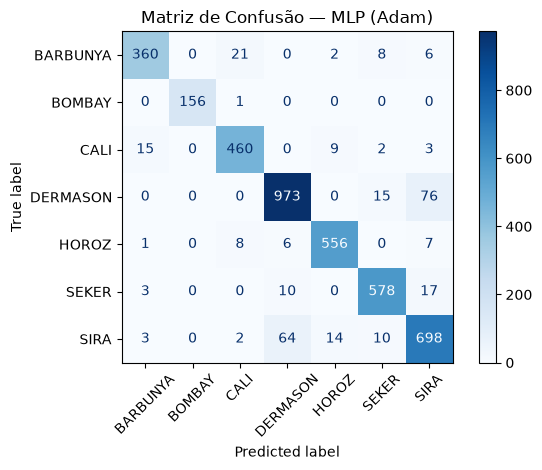

In [35]:

# Item 2 — Avaliando a MLP no conjunto de teste

y_pred = mlp.predict(X_test_scaled)

# Calculando as métricas
acuracia = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="macro")
precisao = precision_score(y_test, y_pred, average="macro", zero_division=0)
revocacao = recall_score(y_test, y_pred, average="macro", zero_division=0)

# Exibindo os resultados
print(f"Acurácia: {acuracia:.4f}")
print(f"F1-Score (macro): {f1:.4f}")
print(f"Precisão (macro): {precisao:.4f}")
print(f"Revocação (macro): {revocacao:.4f}")

# Matriz de confusão
matriz = confusion_matrix(y_test, y_pred, labels=mlp.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=mlp.classes_
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de Confusão — MLP (Adam)")
plt.tight_layout()
plt.show()


In [36]:

# Item 3 — Repetindo o treinamento com Adam por 10 vezes

resultados_adam = []
particoes = []

for i in range(10):
    # Nova partição holdout estratificada
    X_tr, X_te, y_tr, y_te = train_test_split(
        X,
        y,
        test_size=0.30,
        stratify=y,
        random_state=42 + i
    )

    # Escalonamento independente para cada partição
    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr)
    X_te_scaled = scaler.transform(X_te)

    # Guardando a partição para reutilizar com SGD
    particoes.append((X_tr_scaled, X_te_scaled, y_tr, y_te))

    # Treinamento da MLP
    modelo = MLPClassifier(
        hidden_layer_sizes=(10,),
        activation="relu",
        solver="adam",
        max_iter=300,
        verbose=False,
        random_state=42 + i
    )

    modelo.fit(X_tr_scaled, y_tr)
    pred = modelo.predict(X_te_scaled)

    # Avaliação
    resultados_adam.append({
        "Acurácia": accuracy_score(y_te, pred),
        "F1-Score": f1_score(y_te, pred, average="macro")
    })

# Organizando e apresentando os resultados
df_adam = pd.DataFrame(resultados_adam)

print("Resultados das 10 repetições — Adam:")
print(df_adam.round(4))

print("\nMédia:")
print(df_adam.mean().round(4))

print("\nDesvio padrão:")
print(df_adam.std().round(4))


c:\Users\ricar\OneDrive\Documentos\Trabalho_Pratico_Redes_Neurais_2.2\venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\ricar\OneDrive\Documentos\Trabalho_Pratico_Redes_Neurais_2.2\venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


Resultados das 10 repetições — Adam:
   Acurácia  F1-Score
0    0.9258    0.9368
1    0.9278    0.9398
2    0.9297    0.9406
3    0.9236    0.9342
4    0.9256    0.9380
5    0.9317    0.9423
6    0.9292    0.9395
7    0.9344    0.9447
8    0.9297    0.9403
9    0.9256    0.9370

Média:
Acurácia    0.9283
F1-Score    0.9393
dtype: float64

Desvio padrão:
Acurácia    0.0033
F1-Score    0.0030
dtype: float64


In [37]:

# Item 4 — Repetindo o treinamento com SGD por 10 vezes

resultados_sgd = []

for i, (X_tr, X_te, y_tr, y_te) in enumerate(particoes):
    # Treinamento da MLP com SGD
    modelo = MLPClassifier(
        hidden_layer_sizes=(10,),
        activation="relu",
        solver="sgd",
        max_iter=300,
        verbose=False,
        random_state=42 + i
    )

    modelo.fit(X_tr, y_tr)
    pred = modelo.predict(X_te)

    # Avaliação
    resultados_sgd.append({
        "Acurácia": accuracy_score(y_te, pred),
        "F1-Score": f1_score(y_te, pred, average="macro")
    })

# Organizando e apresentando os resultados
df_sgd = pd.DataFrame(resultados_sgd)

print("Resultados das 10 repetições — SGD:")
print(df_sgd.round(4))

print("\nMédia:")
print(df_sgd.mean().round(4))

print("\nDesvio padrão:")
print(df_sgd.std().round(4))


c:\Users\ricar\OneDrive\Documentos\Trabalho_Pratico_Redes_Neurais_2.2\venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\ricar\OneDrive\Documentos\Trabalho_Pratico_Redes_Neurais_2.2\venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


Resultados das 10 repetições — SGD:
   Acurácia  F1-Score
0    0.9226    0.9347
1    0.9251    0.9373
2    0.9270    0.9378
3    0.9170    0.9295
4    0.9187    0.9297
5    0.9234    0.9355
6    0.9251    0.9343
7    0.9312    0.9407
8    0.9263    0.9360
9    0.9212    0.9330

Média:
Acurácia    0.9238
F1-Score    0.9348
dtype: float64

Desvio padrão:
Acurácia    0.0042
F1-Score    0.0035
dtype: float64


In [38]:
# Item 5 — Comparando o desempenho dos otimizadores
-- TO DO

SyntaxError: invalid syntax (3325502842.py, line 2)

## Discussão

Nos passos anteriores, você avaliou o desempenho de uma única arquitetura de rede neural, com uma única camada oculta de 10 neurônios e função de ativação ReLU. O otimizador utilizado, seja o SGD ou o Adam, é o algoritmo que usa o gradiente do erro (calculado pela retropropagação) para atualizar os pesos da rede. Neste sentido, a escolha do otimizador é um hiperparâmetro: ela é definida antes do treinamento, não é aprendida a partir dos dados e controla como a rede será treinada. Também são hiperparâmetros a quantidade de camadas ocultas, o número de neurônios, a função de ativação, a quantidade de épocas, a taxa de aprendizado inicial, dentre outros. Já os parâmetros da rede são os pesos e os vieses, ajustados durante o treinamento.

Cabe salientar também que você efetuou o treinamento desta rede por 10 vezes e apresentou os resultados em termos de média ± desvio padrão. Lembre-se que em uma rede neural há a inicialização aleatória de pesos e, em consequência, o desempenho está sujeito a uma flutuação estocástica. Além disso, cada repetição utilizou uma nova partição holdout, o que introduz uma segunda fonte de variação. A execução múltipla das repetições reduz a influência de uma boa ou má "sorte" na escolha dos pesos iniciais e da partição, que poderia distorcer a conclusão no caso de uma única execução, e permite estimar a variabilidade do desempenho por meio do desvio padrão.

Você também aprendeu uma estratégia para escalonar os atributos para uma melhor convergência da rede. Utilize-a em todos os treinamentos e testes propostos a seguir.

## Propondo Novas Arquiteturas

Variando a arquitetura da rede (uma ou duas camadas ocultas, com diferentes números de neurônios em cada uma delas, e a função de ativação) e os hiperparâmetros solver (Adam ou SGD) e número máximo de épocas (100, 150 e 200), atenda ao que se pede:

1. Proponha 10 arquiteturas distintas de RNAs para o problema em questão, à sua escolha
2. Avalie cada uma das arquiteturas perante todas as combinações de hiperparâmetros (2 solvers × 3 números de épocas), repetindo cada treinamento/avaliação por 10 vezes  
    2.1 Cada repetição deve utilizar uma nova partição holdout 70/30 estratificada, com o escalonamento ajustado apenas com os dados de treino, e as mesmas 10 partições devem ser usadas em todas as configurações, para que a comparação seja justa  
    2.2 Ao todo, serão 60 configurações (10 arquiteturas × 2 solvers × 3 números de épocas) e 600 treinamentos
3. Como resultado da avaliação, apresente, com base no conjunto de teste:  
    3.1 As 3 melhores configurações (arquitetura + solver + número de épocas) no tocante ao F-Score (média macro) e à acurácia, considerando a média das 10 repetições (± desvio padrão)  
    3.2 Para cada uma dessas 3 configurações, a repetição em que houve o melhor desempenho: apresente a matriz de confusão e ilustre, para cada classe, os valores de VP (verdadeiros positivos), VN (verdadeiros negativos), FP (falsos positivos) e FN (falsos negativos)

## Estimando o número de neurônios

Um dos problemas de pesquisa com redes neurais artificiais consiste na determinação do número de neurônios em sua arquitetura. Embora não seja possível definir a priori qual rede neural é adequada para um problema, pois isto só pode ser determinado empiricamente, mediante a avaliação de várias arquiteturas, há regras na literatura que sugerem o número de neurônios escondidos, tal como a regra da Pirâmide Geométrica, dada a seguir:

$$N_h = \alpha \cdot \sqrt{N_i \cdot N_o},$$

em que $N_h$ é o número de neurônios ocultos (a serem distribuídos em uma ou duas camadas ocultas), $N_i$ é o número de neurônios na camada de entrada e $N_o$ é o número de neurônios na camada de saída. Como $N_h$ deve ser um número inteiro, arredonde o resultado para o inteiro mais próximo.

1. Consulte a documentação da classe MLPClassifier (disponível em https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) e obtenha os valores de $N_i$ e $N_o$ para a base _Dry Bean_, considerando o número de atributos preditores e o número de classes do problema.
2. Teste os valores de $\alpha$ como sendo iguais a $0.5$, $2$ e $3$.
3. Proponha pelo menos 30 redes neurais segundo a regra da pirâmide geométrica e teste-as nos mesmos termos estabelecidos anteriormente (solver, épocas, 10 repetições com as mesmas partições holdout, escalonamento, etc.)  
    3.1 Apresente as top-3 melhores redes no tocante à F-Score e Acurácia, com base no conjunto de teste

## Considerações Parciais

1. É possível identificar uma rede com desempenho superior às demais? 
2. Qual estratégia mostrou-se mais produtiva para a obtenção de boas arquiteturas (Estratégia Própria ou Pirâmide Geométrica)? Por quê?
3. Um número maior de épocas trouxe melhorias? Justifique com os resultados obtidos, considerando também cada um dos solvers (Adam e SGD)
4. Qual a maior dificuldade de resolução do problema proposto perante as RNAs?